# 04 · Reciclo de licor madre, evaporación al vacío y purga (estacionario)

Resuelve el cristalizador A3110 con reciclo usando **las mismas ecuaciones del modelo dinámico** (`msmpr_core.plant`): el estacionario es `rhs = 0`.

**Advertencia.** Con los parámetros actuales (`C*_ref`, alimentación de KNO3, cinética) los números son *placeholders*: sirven para ver **tendencias y la estructura del balance**, no para citar cifras de planta. Se listan abajo.

**Resultado estructural importante.** Con volumen fijo, la purga la fija el balance de agua (alimentación − evaporación). La fracción `alpha` no cambia cuánto se pierde por purga: cambia cuánto licor circula (tiempo de residencia efectivo).

In [1]:
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
import sys, os
sys.path.insert(0, os.path.abspath(".."))           # raíz del repo (donde está msmpr_core)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from msmpr_core.params import make_params, placeholders, PROVENANCE
from msmpr_core.plant import Plant, simulate
from msmpr_core import control as C
os.makedirs("../docs/fig", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

In [2]:
p = make_params()
print("Parámetros que siguen siendo supuestos:", ", ".join(placeholders()))
pl = Plant(p)

Parámetros que siguen siendo supuestos: feed_dilution_fraction, tank_volume_m3, feed_stock_kg_m3, reference_temperature_C, Cstar_ref_kg_m3, density_k_other, kG_m_s, g, Eg_J_mol, kB_m3_s_inv, b, Kd, cake_moisture_fraction, centrifuge_wash_eff, purge_fraction_alpha, planta_sqm.Cstar_ref_kg_m3, planta_sqm.solubility_slope_K_inv, empirico.vac_limits, empirico.K_TRIM_AIT, empirico.coprecip_threshold_ClO4_g_L, empirico.coprecip_slope_ppm_per_g_L, empirico.moisture_d50_exponent, empirico.rem_eff_d50_exponent, empirico.xS_d50_gains, empirico.level_loop


## 0. Alineación con la base del notebook de calibración
Los `kG`, `kB`, `Kd` de `calibracion_do_crystal.ipynb` solo valen sobre su base. Esta tabla muestra qué difiere de la base con fuentes (`literatura`) y cuáles diferencias condicionan esos parámetros. Para usar valores calibrados: `make_params("calibracion")` + `apply_calibration`.

In [3]:
import sys, os, pathlib
_c = pathlib.Path.cwd()
_raiz = next((p for p in [_c, *_c.parents] if (p / "msmpr_core").is_dir()), None) or next(p for p in _c.glob("*") if (p / "msmpr_core").is_dir())
os.chdir(_raiz / "notebooks")          # rutas relativas ("../docs/fig") validas aunque VS Code abra el kernel en otra carpeta
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))
from msmpr_core.params import diff_bases
diff_bases()

,parametro,literatura,calibracion,condiciona_calibracion
0,feed_stock_kg_m3.ClO4,5.56379,0.003799,False
1,solubility_slope_K_inv,0.03120,0.010000,True
2,rho_crystal_kg_m3,2110.00000,2100.000000,True
3,Kd,0.00200,0.010000,False
4,rho_liquid_kg_m3,1470.00000,1040.000000,True
5,cake_moisture_fraction,0.03000,0.000000,False


## 1. Barrido de la fracción de purga α (T = 40 °C, V fijo)

In [4]:
rows = []
for a in [1.0, 0.75, 0.5, 0.35, 0.25, 0.15, 0.10, 0.05]:
    x, u, d = pl.steady_state(alpha=a)
    m = pl.metrics(x, u, d)
    rows.append({"alpha": a, "reciclo_m3_h": m["recycle_m3_h"], "purga_m3_h": m["purge_m3_h"], "tau_h": m["tau_h"],
                 "evap_t_h": m["evap_t_h"], "sigma": m["sigma"], "Y_%": m["recovery_pct"], "Y_cierre": m["Y_cierre"],
                 "d50_um": m["d50_um"], "ClO4_licor_g_L": m["ClO4_liquor_g_L"], "ppm_ClO4": m["ppm_ClO4"]})
df_alpha = pd.DataFrame(rows).round(4)
df_alpha

,alpha,reciclo_m3_h,purga_m3_h,tau_h,evap_t_h,sigma,Y_%,Y_cierre,d50_um,ClO4_licor_g_L,ppm_ClO4
0,1.00,0.0000,274.9222,2.4007,5.8971,0.0250,13.5782,-0.0,158.7840,5.3990,35.7432
1,0.75,91.6510,274.9529,1.8003,5.8665,0.0296,13.1856,-0.0,140.6901,5.3984,35.7393
2,0.50,275.0053,275.0053,1.2000,5.8142,0.0373,12.5151,-0.0,118.3753,5.3974,35.7325
3,0.35,510.8292,275.0619,0.8398,5.7577,0.0457,11.7917,-0.0,101.4128,5.3963,35.7253
4,0.25,825.3771,275.1257,0.5997,5.6940,0.0551,10.9756,-0.0,87.3720,5.3950,35.7171
5,0.15,1559.7200,275.2447,0.3597,5.5752,0.0727,9.4533,-0.0,69.1175,5.3927,35.7018
6,0.10,2478.2366,275.3596,0.2397,5.4605,0.0896,7.9832,0.0,56.8066,5.3905,35.6870
7,0.05,5236.2441,275.5918,0.1197,5.2288,0.1239,5.0134,0.0,39.2131,5.3860,35.6573


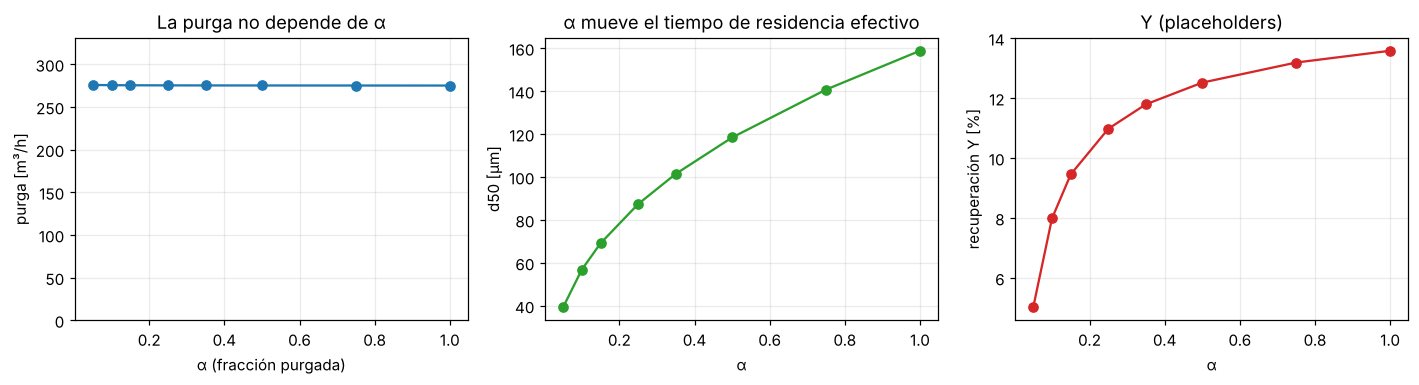

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(df_alpha.alpha, df_alpha.purga_m3_h, "o-"); ax[0].set(xlabel="α (fracción purgada)", ylabel="purga [m³/h]", title="La purga no depende de α", ylim=(0, 1.2*df_alpha.purga_m3_h.max()))
ax[1].plot(df_alpha.alpha, df_alpha.d50_um, "o-", color="tab:green"); ax[1].set(xlabel="α", ylabel="d50 [µm]", title="α mueve el tiempo de residencia efectivo")
ax[2].plot(df_alpha.alpha, df_alpha["Y_%"], "o-", color="tab:red"); ax[2].set(xlabel="α", ylabel="recuperación Y [%]", title="Y (placeholders)")
fig.tight_layout(); fig.savefig("../docs/fig/04_alpha.png"); plt.show()

## 2. Palancas reales del ClO₄⁻: dilución y temperatura

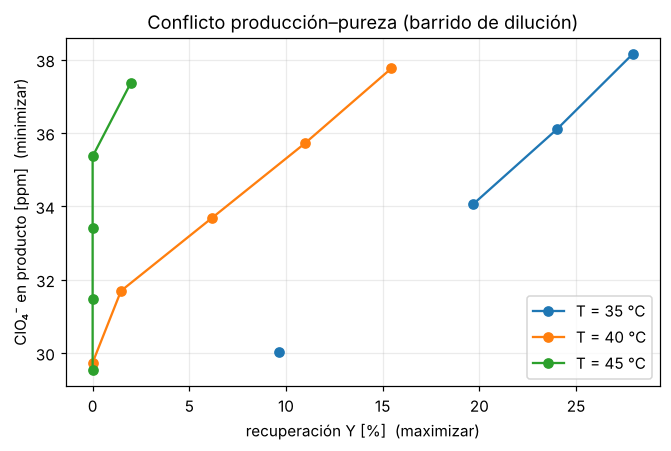

,dilución,T_C,Y_%,ppm_ClO4,d50_um,evap_t_h
0,0.00,35.0,27.945,38.161,107.053,9.769
1,0.00,40.0,15.443,37.759,94.675,6.874
2,0.00,45.0,1.963,37.354,62.402,3.898
3,0.05,35.0,24.005,36.099,102.612,8.608
4,0.05,40.0,10.976,35.717,87.372,5.694
5,0.05,45.0,0.000,35.364,6.170,2.941
6,0.10,35.0,19.669,34.054,97.378,7.449
7,0.10,40.0,6.199,33.695,76.970,4.528
8,0.10,45.0,0.000,33.407,0.000,2.144
9,0.15,35.0,NaN,NaN,NaN,NaN


In [6]:
rows = []
for d_ in [0.0, 0.05, 0.10, 0.15, 0.20]:
    for T in [35.0, 40.0, 45.0]:
        q = make_params(feed_dilution_fraction=d_, crystallizer_temperature_C=T)
        pl_ = Plant(q)
        try:
            x, u, dd = pl_.steady_state()
            m = pl_.metrics(x, u, dd)
            rows.append({"dilución": d_, "T_C": T, "Y_%": m["recovery_pct"], "ppm_ClO4": m["ppm_ClO4"], "d50_um": m["d50_um"], "evap_t_h": m["evap_t_h"]})
        except RuntimeError:
            rows.append({"dilución": d_, "T_C": T, "Y_%": np.nan, "ppm_ClO4": np.nan, "d50_um": np.nan, "evap_t_h": np.nan})
df_ops = pd.DataFrame(rows).round(3)
fig, ax = plt.subplots(figsize=(6.2, 4.2))
for T, g in df_ops.groupby("T_C"):
    ax.plot(g["Y_%"], g.ppm_ClO4, "o-", label=f"T = {T:.0f} °C")
ax.set(xlabel="recuperación Y [%]  (maximizar)", ylabel="ClO₄⁻ en producto [ppm]  (minimizar)", title="Conflicto producción–pureza (barrido de dilución)")
ax.legend(); fig.tight_layout(); fig.savefig("../docs/fig/04_conflicto.png"); plt.show()
df_ops

## Lectura
* La dilución baja el ppm de ClO₄ y también la recuperación: es el conflicto del frente de Pareto de la guía (§7).
* Con los placeholders actuales, a dilución alta o T alta casi no cristaliza (Y→0): la alimentación queda bajo la solubilidad supuesta. Falta medir la solubilidad del licor real.
* El ppm usa un `Kd` supuesto y el ClO₄ de alimentación del informe de parámetros (5.56 g/L, base iónica). Hay que validar ambos antes de leer ppm absolutos.